# Import


In [1]:
# General
import os
import numpy as np
import matplotlib.pyplot as plt
import random
import time
import sys


# model
import tensorflow
import tensorflow as tf
import pickle

import keras
from keras.models import Sequential
# from gradient_accumulator import GradientAccumulateModel

from tensorflow.keras import backend as K


from keras.layers import Add, GlobalAveragePooling2D,Dense, Flatten, Conv2D, Lambda,Input, BatchNormalization, Activation
from tensorflow.keras.utils import Sequence
from keras.utils import to_categorical
# from keras.callbacks import TensorBoard
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras import *
# from tensorflow.keras import layers as Layers
from tensorflow.keras.layers import *
from keras.activations import relu
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.layers import *
from tensorflow.keras import layers, models

# from tensorflow.keras.layers import Add, GlobalAveragePooling2D,Dense, Flatten, Conv2D, Lambda,	Input, BatchNormalization, Activation
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# from keras.utils import to_categorical
from tensorflow.keras.optimizers import *
from tensorflow.keras.callbacks import *
from tensorflow.keras.callbacks import TensorBoard, ModelCheckpoint,EarlyStopping,ReduceLROnPlateau,LambdaCallback

2024-06-09 04:35:43.174113: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-06-09 04:35:43.174223: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-06-09 04:35:43.307017: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Config

In [2]:
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)
tf.config.optimizer.set_jit(True)

In [3]:
sys.path.append('/kaggle/input/resnet-34/')

weight_decay = 1e-4
lr=[5e-3,1e-3,5e-4,1e-4]
num_classes = 10
dropout_rate=0.
BATCH_SIZE = 32
IMG_SIZE = 32
optimizer = AdamW
epoch = 5
loss='categorical_crossentropy'

# Define the directory path
model_dir = "/kaggle/working/"

epoch = 4  # 5th epoch (0-indexed)
batch = 30  # st batch (0-indexed)
layer = 27 # 28th layer (0-indexed)

# Data + Cutmix Augmentation

In [4]:
# BATCH_SIZE = 32
# IMG_SIZE =32
# num_classes = 10


# (X_train, y_train), (X_test, y_test) = cifar10.load_data()


# y_train = to_categorical(y_train, num_classes=num_classes)
# y_test = to_categorical(y_test, num_classes=num_classes)


# X_train = X_train.astype('float32')
# X_test = X_test.astype('float32')


# X_train /= 255.
# X_test /= 255.


# steps = int(X_train.shape[0] / BATCH_SIZE)
# steps_per_epoch = len(X_train) // BATCH_SIZE


# datagen = ImageDataGenerator(
#     rotation_range=15,
#     width_shift_range=0.1,
#     height_shift_range=0.1,
#     horizontal_flip=True,
# )


# class CutMixImageDataGenerator():
#     def __init__(self, generator1, generator2, img_size, batch_size):
#         self.batch_index = 0
#         self.samples = generator1.n
#         self.generator1 = generator1
#         self.generator2 = generator2
#         self.img_size = img_size
#         self.batch_size = batch_size

#     def reset_index(self):
#         self.generator1._set_index_array()
#         self.generator2._set_index_array()

#     def reset(self):
#         self.batch_index = 0
#         self.generator1.reset()
#         self.generator2.reset()
#         self.reset_index()

#     def get_steps_per_epoch(self):
#         quotient, remainder = divmod(self.samples, self.batch_size)
#         return (quotient + 1) if remainder else quotient

#     def __len__(self):
#         return self.get_steps_per_epoch()

#     def __next__(self):
#         if self.batch_index == 0:
#             self.reset()

#         crt_idx = self.batch_index * self.batch_size
#         if crt_idx >= self.samples:
#             self.batch_index = 0
#             raise StopIteration

#         reshape_size = self.batch_size
#         last_step_start_idx = (self.get_steps_per_epoch() - 1) * self.batch_size
#         if crt_idx == last_step_start_idx:
#             reshape_size = self.samples - last_step_start_idx

#         X_1, y_1 = self.generator1.__next__()
#         X_2, y_2 = self.generator2.__next__()

#         cut_ratio = np.random.beta(a=1, b=1, size=reshape_size)
#         cut_ratio = np.clip(cut_ratio, 0.3, 0.7)

#         label_ratio = cut_ratio.reshape(reshape_size, 1)
#         cut_img = X_2

#         X = X_1.copy()
#         for i in range(reshape_size):
#             cut_size = int((self.img_size - 1) * cut_ratio[i])
#             y1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
#             x1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
#             y2 = y1 + cut_size
#             x2 = x1 + cut_size
#             cut_arr = cut_img[i][y1:y2, x1:x2]
#             X[i][y1:y2, x1:x2] = cut_arr

#         y = y_1 * (1 - (label_ratio ** 2)) + y_2 * (label_ratio ** 2)
#         self.batch_index += 1
#         return X, y

#     def __iter__(self):
#         return self

# train_generator1 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
# train_generator2 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)

# train_generator = CutMixImageDataGenerator(
#     generator1=train_generator1,
#     generator2=train_generator2,
#     img_size=IMG_SIZE,
#     batch_size=BATCH_SIZE,
# )

# def generator_wrapper(generator):
#     first_run = True
#     while True:
#         try:
#             X, y = next(generator)
#             if first_run:
#                 print(f'X shape: {X.shape}, y shape: {y.shape}')
#                 first_run = False  # Set the flag to False after printing
#             if X.shape[0] == BATCH_SIZE:
#                 yield X, y
#             elif X.shape[0] < BATCH_SIZE:
#                 # Pad the batch if it is smaller than BATCH_SIZE
#                 X = np.pad(X, ((0, BATCH_SIZE - X.shape[0]), (0, 0), (0, 0), (0, 0)), 'constant')
#                 y = np.pad(y, ((0, BATCH_SIZE - y.shape[0]), (0, 0)), 'constant')
#                 yield X, y
#         except StopIteration:
#             generator.reset()

# train_ds = tf.data.Dataset.from_generator(
#     lambda: generator_wrapper(train_generator),
#     output_signature=(
#         tf.TensorSpec(shape=(BATCH_SIZE, IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
#         tf.TensorSpec(shape=(BATCH_SIZE, num_classes), dtype=tf.float32),
#     )
# )

# train_ds = (train_ds
#             .shuffle(1024)
#             .cache()
#             .repeat()
#             .prefetch(buffer_size=tf.data.experimental.AUTOTUNE))
# # model_cutmix = ResNet34()

# Model (ResNet)

In [5]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.layers import DepthwiseConv2D


class BottleNeck(tf.keras.Model):
    expansion = 4

    def __init__(self, in_channels, out_channels, strides=1, dropout_rate=dropout_rate):
        super(BottleNeck, self).__init__()
        self.conv1 = layers.Conv2D(out_channels, kernel_size=1, use_bias=False)
        self.bn1 = layers.BatchNormalization()
        self.dropout1 = layers.Dropout(dropout_rate)

        # Depthwise convolution followed by pointwise convolution
        self.depthwise_conv = layers.DepthwiseConv2D(kernel_size=3, strides=strides, padding='same', use_bias=False)
        self.pointwise_conv = layers.Conv2D(out_channels, kernel_size=1, use_bias=False)
        # self.conv2 = layers.Conv2D(out_channels, kernel_size=3, strides=strides, padding='same', use_bias=False)
        self.bn2 = layers.BatchNormalization()
        self.dropout2 = layers.Dropout(dropout_rate)


        self.conv3 = layers.Conv2D(self.expansion*out_channels, kernel_size=1, use_bias=False)
        self.bn3 = layers.BatchNormalization()
        self.dropout3 = layers.Dropout(dropout_rate)

        if strides != 1 or in_channels != self.expansion*out_channels:
            self.shortcut = tf.keras.Sequential([
                layers.Conv2D(self.expansion*out_channels, kernel_size=1, strides=strides, use_bias=False),
                layers.BatchNormalization()
            ])
        else:
            self.shortcut = lambda x: x

    def call(self, x, training=True):
        out = tf.keras.activations.relu(self.bn1(self.conv1(x), training=training))
        out = self.dropout1(out, training=training)


        # out = tf.keras.activations.relu(self.bn2(self.conv2(out), training=training))

        out = tf.keras.activations.relu(self.bn2(self.pointwise_conv(self.depthwise_conv(out)), training=training))

        out = self.dropout2(out, training=training)


        out = self.bn3(self.conv3(out), training=training)
        out = self.dropout3(out, training=training)


        out = layers.add([self.shortcut(x), out])
        out = tf.keras.activations.relu(out)
        return out

class BuildResNet(tf.keras.Model):
    def __init__(self, block, num_blocks, num_classes, dropout_rate=dropout_rate):
        super(BuildResNet, self).__init__()
        self.in_channels = 64

        self.conv1 = layers.Conv2D(64, kernel_size=3, strides=1, padding='same', use_bias=False)
        self.bn1 = layers.BatchNormalization()
        self.layer1 = self._make_layer(block, 64, num_blocks[0], strides=1, dropout_rate=dropout_rate)
        self.layer2 = self._make_layer(block, 64, num_blocks[1], strides=2, dropout_rate=dropout_rate)
        self.layer3 = self._make_layer(block, 128, num_blocks[2], strides=2, dropout_rate=dropout_rate)
        self.layer4 = self._make_layer(block, 256, num_blocks[3], strides=2, dropout_rate=dropout_rate)
        self.avg_pool2d = layers.AveragePooling2D(pool_size=4)
        self.flatten = layers.Flatten()
        self.fc = layers.Dense(num_classes, activation='softmax')

    def call(self, x, training=True):
        out = tf.keras.activations.relu(self.bn1(self.conv1(x), training=training))
        out = self.layer1(out, training=training)
        out = self.layer2(out, training=training)
        out = self.layer3(out, training=training)
        out = self.layer4(out, training=training)
        out = self.avg_pool2d(out)
        out = self.flatten(out)
        out = self.fc(out)
        return out

    def _make_layer(self, block, out_channels, num_blocks, strides, dropout_rate):
        stride = [strides] + [1]*(num_blocks-1)
        layers_list = []
        for s in stride:
            layers_list.append(block(self.in_channels, out_channels, s, dropout_rate))
            self.in_channels = out_channels * block.expansion
        return tf.keras.Sequential(layers_list)

def ResNet50(num_classes=num_classes, dropout_rate=dropout_rate):
    return BuildResNet(BottleNeck, [3, 4, 6, 3], num_classes,dropout_rate)


# training with cutmix

In [6]:
class GCAdamW(AdamW):
    def __init__(self, learning_rate, weight_decay, **kwargs):
        super(GCAdamW, self).__init__(learning_rate, weight_decay, **kwargs)

    def get_gradients(self, loss, params):
        # Compute the gradients
        grads = super().get_gradients(loss, params)

        # Centralize the gradients
        centralized_grads = []
        for grad in grads:
            if grad is not None:
                grad_len = len(grad.shape)
                if grad_len > 1:
                    axis = list(range(grad_len - 1))
                    grad -= tf.reduce_mean(grad, axis=axis, keepdims=True)
            centralized_grads.append(grad)

        return centralized_grads

In [7]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[0], weight_decay=1e-4)



# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=32):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:32], y_train[:32]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 280, batch_size=32, callbacks=[callback])



In [8]:
# layer = 27
# specific_gradients_1 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients_2.shape)
# l1 = np.array(specific_gradients_1).flatten()
# d1 = []
# for i in range(1,len(l1)):
#     d1.append(np.linalg.norm(l1[i-1] - l1[i]).item())
# print(d1)

In [9]:
d1 = [0.00012867030454799533, 0.0017292355187237263, 0.001425641356036067, 0.0016544796526432037, 0.0014014213811606169, 0.0020684630144387484, 0.0017891915049403906, 3.83574515581131e-05, 0.009070608764886856, 0.009095565415918827, 0.00696982629597187, 0.006873967591673136, 7.013154390733689e-05, 0.00018002951401285827, 0.0002586235641501844, 0.0001902797957882285, 0.00032334934803657234, 0.0023352056741714478, 0.0011865791166201234, 0.0017959288088604808, 0.004889314994215965, 0.0033170273527503014, 0.0005239032907411456, 0.0007442772621288896, 0.0006455903640016913, 0.00031272260821424425, 4.012512363260612e-06, 0.0032820331398397684, 0.004137957468628883, 0.001163591630756855, 0.00015833739598747343, 0.012445112690329552, 0.012323839589953423, 0.00012042856542393565, 0.004278699401766062, 0.004259660840034485, 2.109689376084134e-05, 0.0005120609421283007, 0.0012682200176641345, 0.005783385131508112, 0.012829016894102097, 0.007847991771996021, 0.014664579182863235, 0.0015369751490652561, 0.0008347653783857822, 0.0028122575022280216, 0.00014332012506201863, 0.0005233095143921673, 0.0009256309713236988, 0.00032504985574632883, 7.62674244469963e-06, 0.00027485977625474334, 0.0002768796111922711, 0.0022151132579892874, 0.0020871139131486416, 0.0044422154314816, 0.0009222662192769349, 0.0011983785079792142, 0.0015863573644310236, 0.0005868426524102688, 0.0010429619578644633, 0.0026553955394774675, 0.0003327945014461875]

In [10]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[1], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])



# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=32):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:32], y_train[:32]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 280, batch_size=32, callbacks=[callback])

In [11]:
# layer= 27
# specific_gradients_2 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients_2.shape)
# l2 = np.array(specific_gradients_2).flatten()
# d2 = []
# for i in range(1,len(l2)):
#     d2.append(np.linalg.norm(l2[i-1] - l2[i]).item())
# print(d2)

In [12]:
d2 = [0.003036326728761196, 0.004254509694874287, 0.0009649544954299927, 0.005301468539983034, 0.0016250519547611475, 0.006256731692701578, 0.011070841923356056, 0.005032396875321865, 0.004609056282788515, 0.0038330373354256153, 0.002391412854194641, 0.007169545628130436, 0.005220147781074047, 0.0008490532636642456, 0.013753507286310196, 0.014269141480326653, 0.0009267333662137389, 0.0077716633677482605, 0.007325679995119572, 0.015051020309329033, 0.007550247944891453, 0.0012799082323908806, 0.006475816946476698, 0.0008773342706263065, 0.01060513686388731, 0.011500518769025803, 0.00882756058126688, 0.011624160222709179, 0.005086456425487995, 0.0008297455497086048, 0.004829369019716978, 0.004621557425707579, 0.0014735509175807238, 0.019442008808255196, 0.027311155572533607, 0.01689089834690094, 0.004078042693436146, 0.002288535702973604, 0.01145918294787407, 0.01453116349875927, 0.0030582877807319164, 0.008215000852942467, 0.012140773236751556, 0.002220070455223322, 0.004470929969102144, 0.008998233824968338, 0.008017286658287048, 2.9599759727716446e-06, 0.001902021816931665, 0.004184849560260773, 0.009510781615972519, 0.016786502674221992, 0.004252276383340359, 0.009301713667809963, 0.003526232438161969, 0.009903283789753914, 0.013086305931210518, 0.008104117587208748, 0.01914132572710514, 0.01622720994055271, 0.009142891503870487, 0.012396100908517838, 0.0035037288907915354]

In [13]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[2], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])



# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

In [14]:
# specific_gradients_3 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients_3.shape)
# l3 = np.array(specific_gradients_3).flatten()
# d3 = []
# for i in range(1,len(l3)):
#     d3.append(np.linalg.norm(l3[i-1] - l3[i]).item())
# print(d3)

In [15]:
d3 = [0.010845503769814968, 0.002585761481896043, 0.003772240597754717, 0.004565776791423559, 0.0050061107613146305, 0.0031336890533566475, 0.010932758450508118, 0.005061190575361252, 0.04154433310031891, 0.032251425087451935, 0.0037441409658640623, 0.004634982440620661, 0.004330608528107405, 0.013675463385879993, 0.01930290460586548, 0.013564832508563995, 0.01593514159321785, 0.011187650263309479, 0.008592884056270123, 0.007497712969779968, 0.004789311904460192, 0.007677578367292881, 0.002213444095104933, 0.009668467566370964, 0.0023055560886859894, 0.0013615406351163983, 0.009119860827922821, 0.013828787952661514, 0.0034481119364500046, 0.0030811848118901253, 0.011281819082796574, 0.006555963307619095, 0.001406427938491106, 0.00345698487944901, 0.009599900804460049, 0.015322758816182613, 0.007319705560803413, 0.002499273046851158, 0.001261653145775199, 0.007713274098932743, 0.004693442955613136, 6.926810601726174e-05, 0.001490532187744975, 0.01596587523818016, 0.011561321094632149, 0.010028406046330929, 0.01039329543709755, 0.005092707462608814, 0.007036999799311161, 0.006432537920773029, 0.008091634139418602, 0.017294393852353096, 0.0028621340170502663, 0.007726616226136684, 0.006998613476753235, 0.0003617249894887209, 0.010424320586025715, 0.009451163932681084, 0.004416791256517172, 0.0006475555710494518, 0.00991072878241539, 0.006328443996608257, 0.0034607055131345987]

In [16]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[3], weight_decay=1e-4)



# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

In [17]:
# specific_gradients_4 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l4 = np.array(specific_gradients_4).flatten()
# d4 = []
# for i in range(1,len(l4)):
#     d4.append(np.linalg.norm(l4[i-1] - l4[i]).item())
# print(d4)

In [18]:
d4 = [0.024636678397655487, 0.12690111994743347, 0.13394668698310852, 0.05742320418357849, 0.0687541589140892, 0.06582057476043701, 0.0937597006559372, 0.1037101298570633, 0.12188591063022614, 0.022578250616788864, 0.06310953199863434, 0.05153532698750496, 0.12834057211875916, 0.08914174139499664, 0.0033096978440880775, 0.05385027453303337, 0.02020278573036194, 0.1904812455177307, 0.020813576877117157, 0.04445226490497589, 0.06905867904424667, 0.06673961877822876, 0.0685025006532669, 0.06355483829975128, 0.05961102992296219, 0.08471289277076721, 0.21164381504058838, 0.13258899748325348, 0.04062791168689728, 0.09331327676773071, 0.019221551716327667, 0.09046553075313568, 0.15438073873519897, 0.008350638672709465, 0.013019533827900887, 0.030978739261627197, 0.07674713432788849, 0.005522221326828003, 0.1678164303302765, 0.15753424167633057, 0.06918556988239288, 0.08968909084796906, 0.10019579529762268, 0.08019623160362244, 0.06167372316122055, 0.24256809055805206, 0.03455003350973129, 0.0012567415833473206, 0.08058595657348633, 0.031696807593107224, 0.039381783455610275, 0.0988280400633812, 0.0836695209145546, 0.0019855648279190063, 0.09192553907632828, 0.05133311450481415, 0.04354121536016464, 0.061835166066884995, 0.05006305128335953, 0.04239283502101898, 0.01687697134912014, 0.003997670486569405, 0.07488267123699188]

# data Augemtn

In [19]:
BATCH_SIZE = 32
IMG_SIZE =32
num_classes = 10


(X_train, y_train), (X_test, y_test) = cifar10.load_data()

y_train = to_categorical(y_train, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)


X_train = X_train.astype('float32')
X_test = X_test.astype('float32')


X_train /= 255.
X_test /= 255.



steps = int(X_train.shape[0] / BATCH_SIZE)

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
)
train_generator = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)  # generate augmented data from training set

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

# create the dataset pipeline
train_ds = (train_ds
            .shuffle(1024)
            .cache()
            .repeat()
            .batch(BATCH_SIZE)
            .prefetch(buffer_size=tf.data.experimental.AUTOTUNE))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


In [20]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[0], weight_decay=1e-4)



# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

In [21]:
# specific_gradients_11 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l11 = np.array(specific_gradients_11).flatten()
# d11 = []
# for i in range(1,len(l11)):
#     d11.append(np.linalg.norm(l11[i-1] - l11[i]).item())
# print(d11)

In [22]:
d11 = [0.016802417114377022, 2.6526744477450848e-05, 0.0008828053250908852, 0.0018026765901595354, 0.053309131413698196, 0.06440171599388123, 0.020030681043863297, 0.008339542895555496, 0.003370105056092143, 0.00045224197674542665, 0.0031722215935587883, 0.0015241000801324844, 0.00032369286054745317, 0.0031487001106142998, 0.00733424536883831, 0.0021831290796399117, 0.002226143376901746, 0.0008724897634238005, 0.0015092894900590181, 0.0026017818599939346, 0.004519293550401926, 0.013777947053313255, 0.01144774816930294, 0.002587453927844763, 0.0001599861279828474, 0.001594901317730546, 0.003340414259582758, 0.015402497723698616, 0.010360021144151688, 0.0006206586840562522, 0.0031514596194028854, 0.0026650321669876575, 0.0015896528493613005, 0.0027889409102499485, 0.020068861544132233, 0.0219070166349411, 6.445462349802256e-05, 0.00010573811596259475, 0.030234668403863907, 0.03023420460522175, 0.0019574433099478483, 0.0009187445393763483, 7.381365867331624e-05, 0.00011945658479817212, 0.0022801782470196486, 0.0261782705783844, 0.028862465173006058, 0.0012182977516204119, 0.013080209493637085, 0.013670777902007103, 0.023631853982806206, 0.022849995642900467, 0.003868347965180874, 0.0011772166471928358, 0.0022482825443148613, 0.001854323549196124, 0.000936748692765832, 0.003946677781641483, 0.0035102791152894497, 0.0046842158772051334, 0.006112540606409311, 0.004278058186173439, 0.005664404481649399]


In [23]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[1], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])


In [24]:
# specific_gradients_12 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l12 = np.array(specific_gradients_12).flatten()
# d12 = []
# for i in range(1,len(l12)):
#     d12.append(np.linalg.norm(l12[i-1] - l12[i]).item())
# print(d12)

In [25]:
d12 = [0.0014269002713263035, 0.0006734622875228524, 0.0001512950548203662, 0.0014361420180648565, 0.0002862574765458703, 0.0007797586731612682, 0.0012783249840140343, 0.00351316318847239, 0.004513727501034737, 0.0030714820604771376, 0.0015044943429529667, 0.0010366513160988688, 0.0019129486754536629, 0.004143794998526573, 0.0051532769575715065, 0.0012391182826831937, 0.0028230720199644566, 0.0007801663596183062, 0.001782547333277762, 0.004645189270377159, 0.00390074634924531, 0.00384117616340518, 0.021120266988873482, 0.017894897609949112, 0.007788907736539841, 0.010923702269792557, 0.0016104297246783972, 0.0016016538720577955, 0.0009980531176552176, 0.0017897867364808917, 0.008949268609285355, 0.005528935231268406, 0.004463295452296734, 0.0008245317731052637, 0.004707606974989176, 0.0060683684423565865, 0.00013771886005997658, 0.004527533892542124, 0.004600476939231157, 0.007156772073358297, 0.002867416711524129, 0.00014836143236607313, 0.001110004959627986, 0.0009177336469292641, 0.0008392807794734836, 0.002494568470865488, 0.004380328580737114, 0.0025066283997148275, 0.0020571332424879074, 0.0014552641659975052, 0.003438148647546768, 0.003773344215005636, 0.007891345769166946, 0.004573917016386986, 0.0006252571474760771, 0.0027061805594712496, 0.0005833829054608941, 0.0011618398129940033, 0.0020575697999447584, 0.0016305462922900915, 0.0004546081181615591, 5.3494470193982124e-05, 0.0035126348957419395]


In [26]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[2], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])


In [27]:
# specific_gradients_13 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l13 = np.array(specific_gradients_13).flatten()
# d13 = []
# for i in range(1,len(l13)):
#     d13.append(np.linalg.norm(l13[i-1] - l13[i]).item())
# print(d13)

In [28]:
d13= [0.011764133349061012, 0.022446438670158386, 0.004792945459485054, 0.02443903498351574, 0.0586162805557251, 0.04370493441820145, 0.011805526912212372, 0.00017652567476034164, 0.002045250264927745, 0.013947702944278717, 0.0030684899538755417, 0.01495752576738596, 0.00021050404757261276, 0.01668153703212738, 0.022302042692899704, 0.00988489855080843, 0.00027002114802598953, 0.004896325059235096, 0.01639639213681221, 0.0010368507355451584, 0.002100953832268715, 0.009042833931744099, 0.0006761137628927827, 0.019066205248236656, 0.007093485444784164, 0.021280378103256226, 0.009523291140794754, 0.005375758744776249, 0.001053706044331193, 0.028279675170779228, 0.03814874589443207, 0.02674105018377304, 0.016512179747223854, 0.012473752722144127, 0.004348142072558403, 0.020090432837605476, 0.008976658806204796, 0.007607640698552132, 0.004382620565593243, 0.019165877252817154, 0.001353621482849121, 0.018830640241503716, 0.0202496200799942, 0.010942197404801846, 0.01723632961511612, 0.029188359156250954, 0.0035381601192057133, 0.0069250790402293205, 0.007254771422594786, 0.013714255765080452, 0.020811980590224266, 0.007570190820842981, 0.017231587320566177, 0.017558598890900612, 0.0025786161422729492, 0.005562915932387114, 0.01173203531652689, 0.001427043229341507, 0.01033643539994955, 0.004531405866146088, 0.009723957628011703, 0.0055299317464232445, 0.003470863215625286]

In [29]:
model = ResNet50()

optimizer = GCAdamW(learning_rate=lr[3], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

Epoch 1/5


I0000 00:00:1717907794.592641     111 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
/opt/conda/lib/python3.10/site-packages/keras/src/backend/tensorflow/trainer.py:603: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight)`.
  warnings.warn(


300/300 ━━━━━━━━━━━━━━━━━━━━ 290s 706ms/step - accuracy: 0.1458 - loss: 2.5093
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 214s 714ms/step - accuracy: 0.2400 - loss: 2.0462
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 214s 713ms/step - accuracy: 0.2871 - loss: 1.9193
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 214s 713ms/step - accuracy: 0.3267 - loss: 1.8506
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 216s 720ms/step - accuracy: 0.3604 - loss: 1.7608


In [30]:
specific_gradients_14 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients.shape)
l14 = np.array(specific_gradients_14).flatten()
d14 = []
for i in range(1,len(l14)):
    d14.append(np.linalg.norm(l14[i-1] - l14[i]).item())
print(d14)

[0.05983348190784454, 0.010135725140571594, 0.14865872263908386, 0.18629901111125946, 0.006258973851799965, 0.08258166909217834, 0.06736506521701813, 0.1330432891845703, 0.09859766066074371, 0.0030279383063316345, 0.07988893985748291, 0.037172138690948486, 0.1429562270641327, 0.22923167049884796, 0.10207286477088928, 0.09371574223041534, 0.08111988008022308, 0.127187117934227, 0.04378770291805267, 0.1418275684118271, 0.3527089059352875, 0.09407342970371246, 0.11890797317028046, 0.10645091533660889, 0.07065432518720627, 0.22719362378120422, 0.22417475283145905, 0.07515756785869598, 0.019880261272192, 0.05980765447020531, 0.030261343345046043, 0.08384494483470917, 0.08359912037849426, 0.11196500062942505, 0.21925082802772522, 0.027473904192447662, 0.19563838839530945, 0.13373242318630219, 0.16958793997764587, 0.06842893362045288, 0.22373175621032715, 0.2821860909461975, 0.2795361578464508, 0.38703423738479614, 0.05332040786743164, 0.07375416159629822, 0.14866489171981812, 0.2008114755153

In [31]:
d14 = [0.05983348190784454, 0.010135725140571594, 0.14865872263908386, 0.18629901111125946, 0.006258973851799965, 0.08258166909217834, 0.06736506521701813, 0.1330432891845703, 0.09859766066074371, 0.0030279383063316345, 0.07988893985748291, 0.037172138690948486, 0.1429562270641327, 0.22923167049884796, 0.10207286477088928, 0.09371574223041534, 0.08111988008022308, 0.127187117934227, 0.04378770291805267, 0.1418275684118271, 0.3527089059352875, 0.09407342970371246, 0.11890797317028046, 0.10645091533660889, 0.07065432518720627, 0.22719362378120422, 0.22417475283145905, 0.07515756785869598, 0.019880261272192, 0.05980765447020531, 0.030261343345046043, 0.08384494483470917, 0.08359912037849426, 0.11196500062942505, 0.21925082802772522, 0.027473904192447662, 0.19563838839530945, 0.13373242318630219, 0.16958793997764587, 0.06842893362045288, 0.22373175621032715, 0.2821860909461975, 0.2795361578464508, 0.38703423738479614, 0.05332040786743164, 0.07375416159629822, 0.14866489171981812, 0.2008114755153656, 0.2155868411064148, 0.12114669382572174, 0.13122497498989105, 0.013165408745408058, 0.06802816689014435, 0.12468422949314117, 0.04068562760949135, 0.013837385922670364, 0.03154147416353226, 0.3073163628578186, 0.19637200236320496, 0.08588448166847229, 0.17497137188911438, 0.105970598757267, 0.14000514149665833]


#### Convmixer 10

#### convmixer 100

In [37]:
min_curve_cutmix = []
max_curve_cutmix = []
for i in range(len(d1)):
    min_curve_cutmix.append(np.min([d1[i], d2[i], d3[i], d4[i]]))
    max_curve_cutmix.append(np.max([d1[i], d2[i], d3[i], d4[i]]))


In [38]:
min_curve = []
max_curve= []
for i in range(len(d1)):
    min_curve.append(np.min([d11[i], d12[i], d13[i], d14[i]]))
    max_curve.append(np.max([d11[i], d12[i], d13[i], d14[i]]))


In [34]:
print(d14)

[0.05983348190784454, 0.010135725140571594, 0.14865872263908386, 0.18629901111125946, 0.006258973851799965, 0.08258166909217834, 0.06736506521701813, 0.1330432891845703, 0.09859766066074371, 0.0030279383063316345, 0.07988893985748291, 0.037172138690948486, 0.1429562270641327, 0.22923167049884796, 0.10207286477088928, 0.09371574223041534, 0.08111988008022308, 0.127187117934227, 0.04378770291805267, 0.1418275684118271, 0.3527089059352875, 0.09407342970371246, 0.11890797317028046, 0.10645091533660889, 0.07065432518720627, 0.22719362378120422, 0.22417475283145905, 0.07515756785869598, 0.019880261272192, 0.05980765447020531, 0.030261343345046043, 0.08384494483470917, 0.08359912037849426, 0.11196500062942505, 0.21925082802772522, 0.027473904192447662, 0.19563838839530945, 0.13373242318630219, 0.16958793997764587, 0.06842893362045288, 0.22373175621032715, 0.2821860909461975, 0.2795361578464508, 0.38703423738479614, 0.05332040786743164, 0.07375416159629822, 0.14866489171981812, 0.2008114755153

# getting plots together

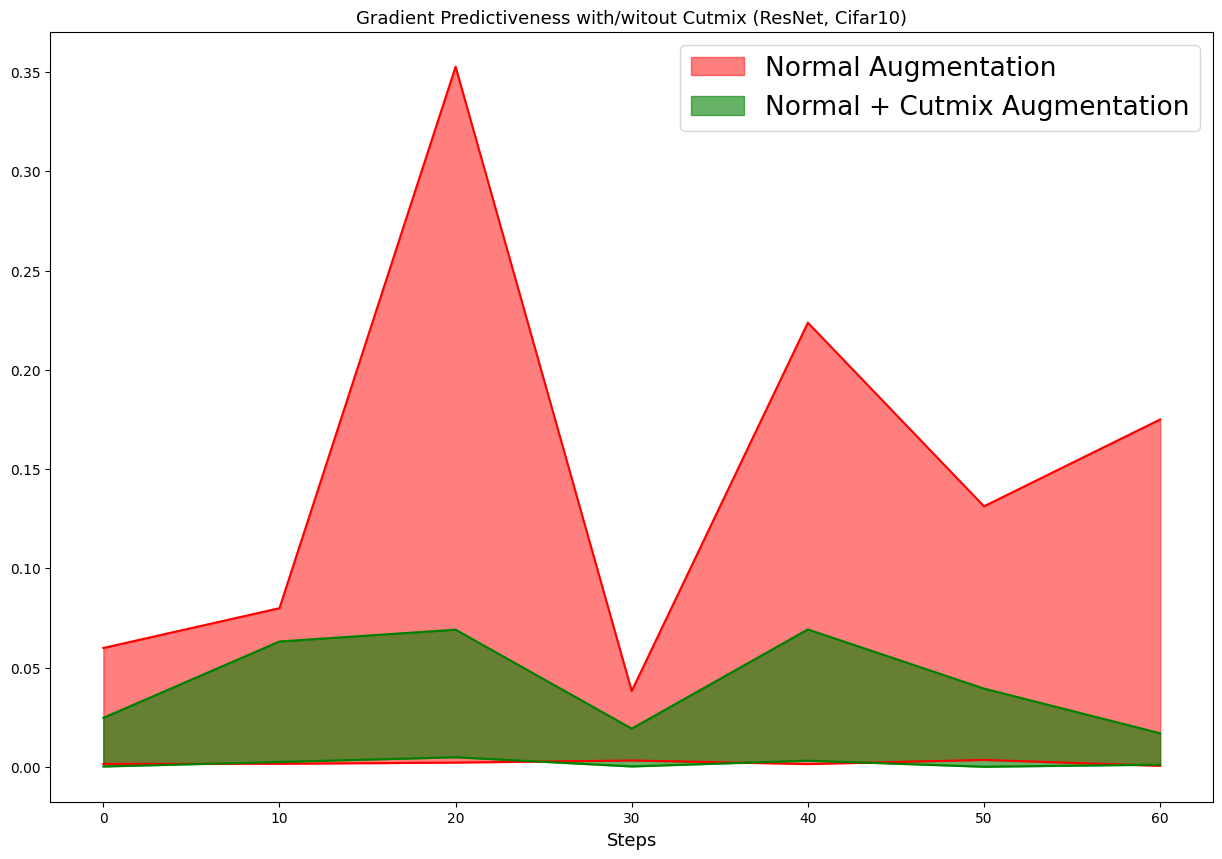

In [35]:
step = 10
steps = np.arange(0, len(min_curve), step)
plt.figure(figsize=(15, 10))
plt.fill_between(steps, min_curve[::step], max_curve[::step],
                alpha=.5, color='red', label='Normal Augmentation')
plt.plot(steps, min_curve[::step], color='red')
plt.plot(steps, max_curve[::step], color='red')

plt.fill_between(steps, min_curve_cutmix[::step], max_curve_cutmix[::step],
                alpha=0.6, color='Green', label='Normal + Cutmix Augmentation')
plt.plot(steps, min_curve_cutmix[::step], color='Green')
plt.plot(steps, max_curve_cutmix[::step], color='Green')

plt.legend(fontsize=19)
plt.title('Gradient Predictiveness', fontsize=20)

plt.xlabel('Steps', fontsize=13)
plt.title('Gradient Predictiveness with/witout Cutmix (ResNet, Cifar10)', fontsize=13)

# plt.savefig(os.path.join(figures_path, 'gradient_predictiveness.png'), dpi=500, quality=100)
plt.show()

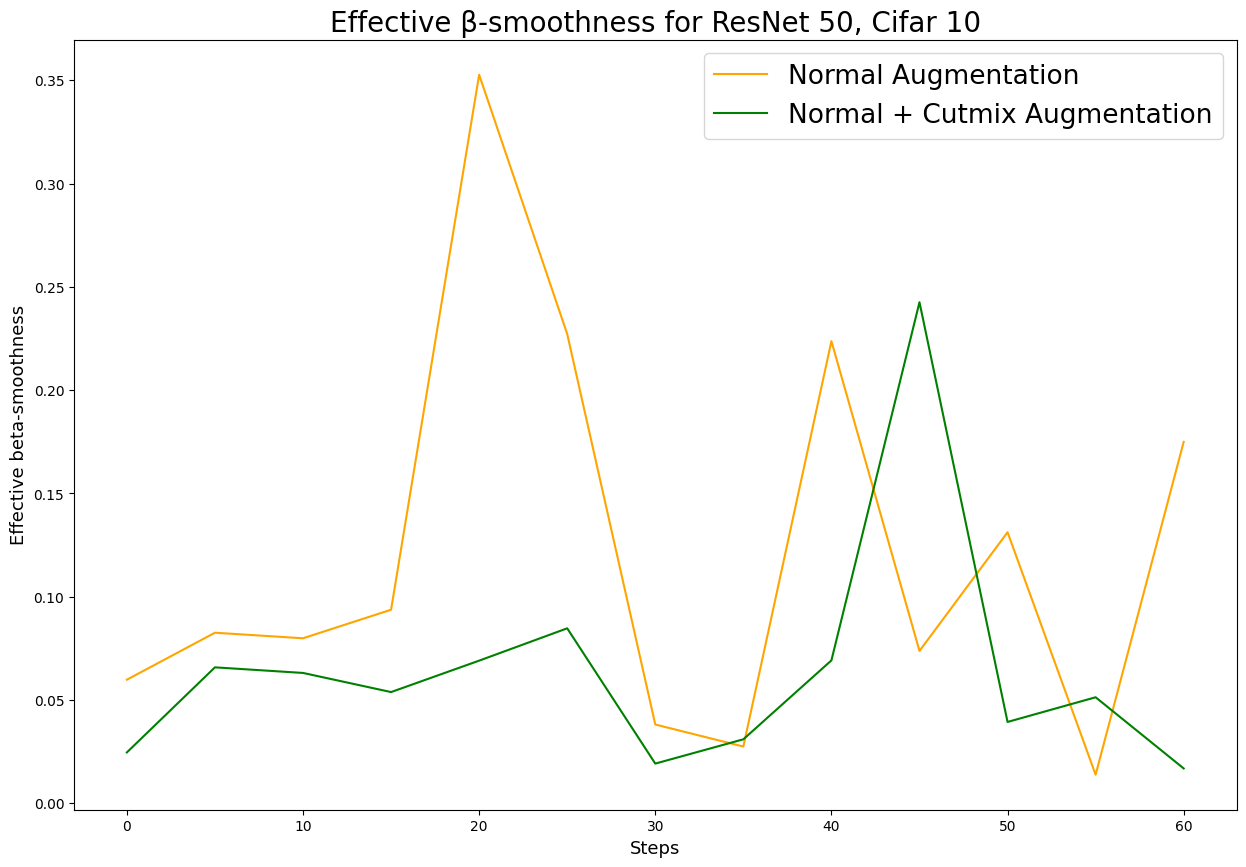

In [ ]:
step = 5
steps = np.arange(0, len(min_curve), step)
plt.figure(figsize=(15, 10))

plt.plot(steps, max_curve[::step], color='orange', label='Normal Augmentation')

plt.plot(steps, max_curve_cutmix[::step], color='green', label='Normal + Cutmix Augmentation')

plt.legend(fontsize=19)
plt.title('Effective β-smoothness for ResNet 50, Cifar 10', fontsize=20)
plt.ylabel('Effective beta-smoothness', fontsize=13)
plt.xlabel('Steps', fontsize=13)
# plt.savefig(os.path.join(figures_path, 'effective_beta_smoothness.png'), dpi=500, quality=100)
plt.show()